<a href="https://colab.research.google.com/github/officialanushka3003-dotcom/Predictive-Analytics-of-E-learning-Dropouts/blob/main/Predicitve_analytics_of_elearningdropouts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#loading the dataset
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("File:", filename)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Saving online_learning_engagement_dropout_risk.csv to online_learning_engagement_dropout_risk.csv
Dataset loaded successfully!
File: online_learning_engagement_dropout_risk.csv
Number of rows: 2800
Number of columns: 11


Inspecting the actual column

In [2]:
print("COLUMN NAMES")
print(df.columns.tolist())

print("\nFIRST 10 ROWS")
display(df.head(10))

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDUPLICATE ROWS:", df.duplicated().sum())


COLUMN NAMES
['student_id', 'course_category', 'login_frequency_per_week', 'avg_session_minutes', 'course_progress_percent', 'assignments_completed', 'quiz_average_score', 'forum_interactions', 'video_watch_percent', 'device_type', 'dropout_risk']

FIRST 10 ROWS


,student_id,course_category,login_frequency_per_week,avg_session_minutes,course_progress_percent,assignments_completed,quiz_average_score,forum_interactions,video_watch_percent,device_type,dropout_risk
0,1,Design,14,17,51,7,60.42,14,23,Desktop,Low
1,2,AI & ML,8,26,1,10,77.25,33,29,Tablet,Medium
2,3,Business,6,26,24,1,93.46,23,82,Desktop,Low
3,4,AI & ML,5,99,12,7,69.77,32,92,Desktop,Low
4,5,AI & ML,13,150,97,3,89.48,40,34,Tablet,Low
5,6,Programming,4,154,50,9,64.13,40,82,Desktop,Low
6,7,Business,8,175,57,9,46.14,44,38,Desktop,Medium
7,8,Business,1,90,33,0,43.69,39,82,Tablet,Low
8,9,Business,14,87,34,4,43.08,26,75,Mobile,High
9,10,AI & ML,9,15,2,0,62.81,20,40,Desktop,Low



DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2800 entries, 0 to 2799
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   student_id                2800 non-null   int64  
 1   course_category           2800 non-null   object 
 2   login_frequency_per_week  2800 non-null   int64  
 3   avg_session_minutes       2800 non-null   int64  
 4   course_progress_percent   2800 non-null   int64  
 5   assignments_completed     2800 non-null   int64  
 6   quiz_average_score        2800 non-null   float64
 7   forum_interactions        2800 non-null   int64  
 8   video_watch_percent       2800 non-null   int64  
 9   device_type               2800 non-null   object 
 10  dropout_risk              2800 non-null   object 
dtypes: float64(1), int64(7), object(3)
memory usage: 240.8+ KB

MISSING VALUES
student_id                  0
course_category             0
login_

Step 3: Finding possible dropout target columns

In [3]:
keywords = [
    "dropout", "target", "status", "outcome",
    "risk", "completion", "completed", "withdraw",
    "retention", "enrolled", "graduat"
]

candidates = [
    col for col in df.columns
    if any(word in col.lower() for word in keywords)
]

print("Potential target columns:", candidates)

for col in candidates:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts(dropna=False).head(20))


Potential target columns: ['assignments_completed', 'dropout_risk']

--- assignments_completed ---
Unique values: 12
assignments_completed
11    262
9     248
4     244
2     242
5     242
6     237
7     232
10    226
3     224
0     222
8     219
1     202
Name: count, dtype: int64

--- dropout_risk ---
Unique values: 3
dropout_risk
Low       1360
Medium     847
High       593
Name: count, dtype: int64


Checking dataset quality

In [4]:
print("Dataset shape:", df.shape)

print("\nNumeric column summary:")
display(df.describe().T)

print("\nCategorical column summary:")
display(df.describe(include=["object", "category"]).T)

print("\nMissing values as percentages:")
missing_pct = (df.isnull().mean() * 100).round(2)
print(missing_pct[missing_pct > 0].sort_values(ascending=False))


Dataset shape: (2800, 11)

Numeric column summary:


,count,mean,std,min,25%,50%,75%,max
student_id,2800.0,1400.500000,808.434702,1.00,700.75,1400.50,2100.250,2800.00
login_frequency_per_week,2800.0,7.498571,4.032557,1.00,4.00,8.00,11.000,14.00
avg_session_minutes,2800.0,94.236786,48.937770,10.00,52.00,94.00,136.000,179.00
course_progress_percent,2800.0,50.601786,29.157302,0.00,25.00,52.00,76.000,100.00
assignments_completed,2800.0,5.612857,3.445816,0.00,3.00,6.00,9.000,11.00
quiz_average_score,2800.0,70.130061,17.395494,40.01,55.11,69.91,85.515,99.98
forum_interactions,2800.0,24.644286,14.642357,0.00,12.00,24.00,37.000,49.00
video_watch_percent,2800.0,60.263571,23.583951,20.00,39.00,60.00,81.000,100.00



Categorical column summary:


,count,unique,top,freq
course_category,2800,5,Design,581
device_type,2800,3,Desktop,957
dropout_risk,2800,3,Low,1360



Missing values as percentages:
Series([], dtype: float64)


In [5]:
# STEP 5: Inspect possible target columns

print("ALL DATASET COLUMNS:")
for col in df.columns:
    print(f"- {col} ({df[col].dtype})")

print("\nPOSSIBLE TARGET COLUMNS:")

keywords = [
    "dropout", "target", "status", "outcome",
    "risk", "completion", "withdraw", "retention"
]

candidates = [
    col for col in df.columns
    if any(word in col.lower() for word in keywords)
]

if candidates:
    for col in candidates:
        print(f"\nColumn: {col}")
        print("Unique values:", df[col].nunique())
        print(df[col].value_counts(dropna=False).head(15))
else:
    print("No obvious target column found. We need to inspect the columns manually.")

print("\nDATASET SIZE:", df.shape)


ALL DATASET COLUMNS:
- student_id (int64)
- course_category (object)
- login_frequency_per_week (int64)
- avg_session_minutes (int64)
- course_progress_percent (int64)
- assignments_completed (int64)
- quiz_average_score (float64)
- forum_interactions (int64)
- video_watch_percent (int64)
- device_type (object)
- dropout_risk (object)

POSSIBLE TARGET COLUMNS:

Column: dropout_risk
Unique values: 3
dropout_risk
Low       1360
Medium     847
High       593
Name: count, dtype: int64

DATASET SIZE: (2800, 11)


EDA

Dropout risk distribution:
dropout_risk
Low       1360
Medium     847
High       593
Name: count, dtype: int64

Risk percentages:
dropout_risk
Low       48.57
Medium    30.25
High      21.18
Name: proportion, dtype: float64


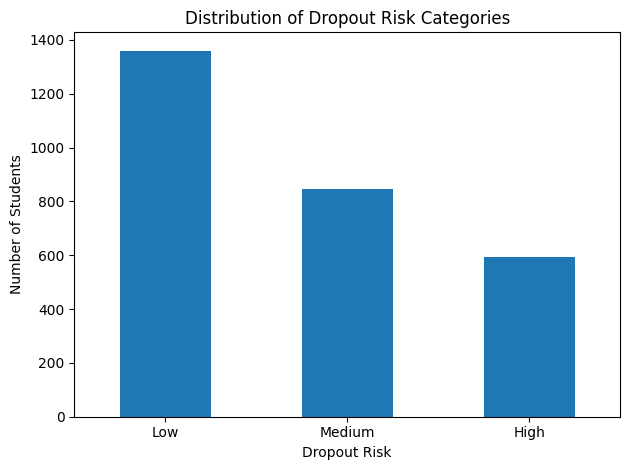


Average engagement measures by risk category:


,login_frequency_per_week,avg_session_minutes,course_progress_percent,assignments_completed,quiz_average_score,forum_interactions,video_watch_percent
dropout_risk,,,,,,,
High,7.40,93.58,53.20,5.71,71.01,24.08,59.54
Low,7.53,94.27,49.97,5.63,69.70,24.84,60.36
Medium,7.52,94.64,49.81,5.52,70.21,24.73,60.61


In [9]:

import matplotlib.pyplot as plt

# 1. Check the number of students in each risk category
print("Dropout risk distribution:")
print(df["dropout_risk"].value_counts())

print("\nRisk percentages:")
print((df["dropout_risk"].value_counts(normalize=True) * 100).round(2))

# 2. Visualize risk categories
df["dropout_risk"].value_counts().reindex(
    ["Low", "Medium", "High"]
).plot(kind="bar", rot=0)

plt.title("Distribution of Dropout Risk Categories")
plt.xlabel("Dropout Risk")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# 3. Explore engagement by risk category
engagement_cols = [
    "login_frequency_per_week",
    "avg_session_minutes",
    "course_progress_percent",
    "assignments_completed",
    "quiz_average_score",
    "forum_interactions",
    "video_watch_percent"
]

print("\nAverage engagement measures by risk category:")
display(df.groupby("dropout_risk")[engagement_cols].mean().round(2))


Checking  whether engagement patterns differ by risk

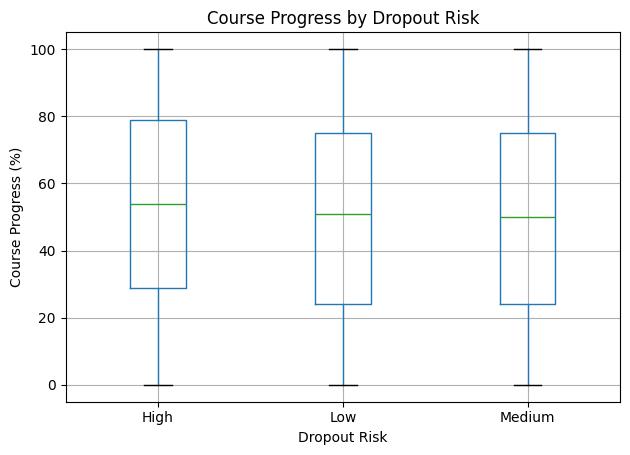

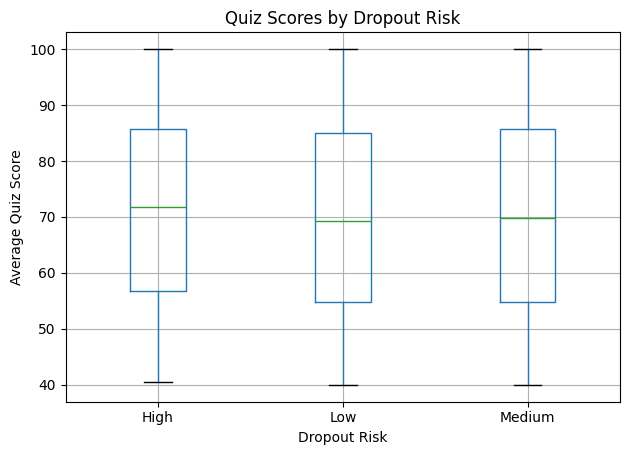

login_frequency_per_week              avg_session_minutes         \
                                 mean median   std                mean median   
dropout_risk                                                                    
High                             7.40    7.0  4.01               93.58   95.0   
Low                              7.53    8.0  4.05               94.27   94.0   
Medium                           7.52    8.0  4.03               94.64   93.0   

                    course_progress_percent                \
                std                    mean median    std   
dropout_risk                                                
High          49.04                   53.20   54.0  28.93   
Low           48.76                   49.97   51.0  29.28   
Medium        49.21                   49.81   50.0  29.05   

             assignments_completed  ...       quiz_average_score         \
                              mean  ...   std               mean median   
dropout_risk                        ...                                   
High                          5.71  ...  3.41              71.01  71.79   
Low                           5.63  ...  3.44              69.70  69.25   
Medium                        5.52  ...  3.48              70.21  69.89   

                    forum_interactions               video_watch_percent  \
                std               mean median    std                mean   
dropout_risk                                                               
High          17.31              24.08   24.0  14.99               59.54   
Low           17.33              24.84   25.0  14.39               60.36   
Medium        17.56              24.73   25.0  14.81               60.61   

                            
             median    std  
dropout_risk                
High           59.0  23.62  
Low            61.0  23.80  
Medium         61.0  23.22  

[3 rows x 21 columns]

In [12]:

# Compare course progress across risk categories
df.boxplot(
    column="course_progress_percent",
    by="dropout_risk"
)

plt.title("Course Progress by Dropout Risk")
plt.suptitle("")
plt.xlabel("Dropout Risk")
plt.ylabel("Course Progress (%)")
plt.tight_layout()
plt.show()

# Compare quiz scores across risk categories
df.boxplot(
    column="quiz_average_score",
    by="dropout_risk"
)

plt.title("Quiz Scores by Dropout Risk")
plt.suptitle("")
plt.xlabel("Dropout Risk")
plt.ylabel("Average Quiz Score")
plt.tight_layout()
plt.show()


# STEP 7B: Full engagement comparison

engagement_cols = [
    "login_frequency_per_week",
    "avg_session_minutes",
    "course_progress_percent",
    "assignments_completed",
    "quiz_average_score",
    "forum_interactions",
    "video_watch_percent"
]

summary = df.groupby("dropout_risk")[engagement_cols].agg(
    ["mean", "median", "std"]
).round(2)

display(summary)



Save a clean working copy

In [14]:

# Preserve the original dataframe
df_clean = df.copy()

# Remove surrounding spaces from text values
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Check that labels remain consistent
print("Risk labels:", sorted(df_clean["dropout_risk"].unique()))
print("Working dataset shape:", df_clean.shape)

# Save the working copy
df_clean.to_csv("online_learning_dropout_clean.csv", index=False)

print("Cleaned working copy saved successfully!")


Risk labels: ['High', 'Low', 'Medium']
Working dataset shape: (2800, 11)
Cleaned working copy saved successfully!


In [13]:

# STEP 8: Inspect target labels and potential predictors

print("Target column: dropout_risk")
print("\nTarget labels:")
print(df_clean["dropout_risk"].value_counts(dropna=False))

# Compare engagement patterns with the risk labels
print("\nMean engagement values by risk:")
display(
    df_clean.groupby("dropout_risk")[
        [
            "login_frequency_per_week",
            "avg_session_minutes",
            "course_progress_percent",
            "assignments_completed",
            "quiz_average_score",
            "forum_interactions",
            "video_watch_percent"
        ]
    ].mean().round(2)
)

# Check categorical columns
print("\nCourse categories:")
print(df_clean["course_category"].value_counts())

print("\nDevice types:")
print(df_clean["device_type"].value_counts())


Target column: dropout_risk

Target labels:
dropout_risk
Low       1360
Medium     847
High       593
Name: count, dtype: int64

Mean engagement values by risk:


,login_frequency_per_week,avg_session_minutes,course_progress_percent,assignments_completed,quiz_average_score,forum_interactions,video_watch_percent
dropout_risk,,,,,,,
High,7.40,93.58,53.20,5.71,71.01,24.08,59.54
Low,7.53,94.27,49.97,5.63,69.70,24.84,60.36
Medium,7.52,94.64,49.81,5.52,70.21,24.73,60.61



Course categories:
course_category
Design          581
AI & ML         567
Data Science    567
Programming     557
Business        528
Name: count, dtype: int64

Device types:
device_type
Desktop    957
Tablet     924
Mobile     919
Name: count, dtype: int64


In [15]:
# STEP 9: Separate features (X) and target (y)

from sklearn.model_selection import train_test_split

# Work from the cleaned dataset
model_df = df_clean.copy()

# Standardize target text
model_df["dropout_risk"] = (
    model_df["dropout_risk"].astype(str).str.strip().str.title()
)

# Check target labels
print("Target class counts:")
print(model_df["dropout_risk"].value_counts())

# Remove rows with missing target labels, if any
model_df = model_df.dropna(subset=["dropout_risk"])

# Separate target and input features
y = model_df["dropout_risk"]

X = model_df.drop(
    columns=["dropout_risk", "student_id"],
    errors="ignore"
)

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nInput features:")
print(X.columns.tolist())
print("\nTarget classes:", sorted(y.unique()))


Target class counts:
dropout_risk
Low       1360
Medium     847
High       593
Name: count, dtype: int64

Feature matrix shape: (2800, 9)
Target shape: (2800,)

Input features:
['course_category', 'login_frequency_per_week', 'avg_session_minutes', 'course_progress_percent', 'assignments_completed', 'quiz_average_score', 'forum_interactions', 'video_watch_percent', 'device_type']

Target classes: ['High', 'Low', 'Medium']


In [16]:

# STEP 10: Create training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))


Training records: 2240
Testing records: 560

Training class distribution (%):
dropout_risk
Low       48.57
Medium    30.27
High      21.16
Name: proportion, dtype: float64

Testing class distribution (%):
dropout_risk
Low       48.57
Medium    30.18
High      21.25
Name: proportion, dtype: float64
